In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("default")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Environment setup completed.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Environment setup completed.
Pandas version: 2.3.3
NumPy version: 2.3.5


In [2]:
DATA_PATH = Path("student_health_dataset_50k.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}\n"
        "Place the CSV beside your notebook or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully.
Shape: (50000, 16)
Rows: 50000
Columns: 16


,student_id,timestamp,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender,health_condition
0,1102,2025-01-01 00:00:00,9.29,67.4,28.56,2113.0,5227,91.3,2.08,veg,high,average,active,yes,other,at-risk
1,1435,2025-01-01 01:00:00,9.33,57.2,30.17,2060.0,14460,67.0,2.57,veg,medium,average,active,occasional,male,at-risk
2,1860,2025-01-01 02:00:00,8.33,73.7,19.93,2236.0,14589,52.6,1.93,non-veg,high,average,active,no,other,at-risk
3,1270,2025-01-01 03:00:00,5.60,61.9,22.02,2650.0,12618,55.2,2.97,veg,high,average,active,no,other,unhealthy
4,1106,2025-01-01 04:00:00,9.10,69.6,20.85,1985.0,14518,27.1,3.09,non-veg,medium,poor,sedentary,occasional,male,at-risk


In [3]:
schema = pd.DataFrame({
    "column": df.columns,
    "data_type": df.dtypes.astype(str).values,
    "unique_values": [
        df[col].nunique(dropna=False) for col in df.columns
    ],
    "missing_values": df.isna().sum().values
})

display(schema)

,column,data_type,unique_values,missing_values
0,student_id,int64,1000,0
1,timestamp,object,50000,0
2,sleep_duration,float64,700,0
3,heart_rate,float64,585,0
4,bmi,float64,1627,0
5,calorie_expenditure,float64,2179,0
6,step_count,int64,13601,0
7,exercise_duration,float64,1041,0
8,water_intake,float64,412,0
9,diet_type,object,3,0


In [4]:
TARGET = "health_condition"
ID_COLUMN = "student_id"
TIME_COLUMN = "timestamp"

NUMERIC_FEATURES = [
    "sleep_duration",
    "heart_rate",
    "bmi",
    "calorie_expenditure",
    "step_count",
    "exercise_duration",
    "water_intake",
]

CATEGORICAL_FEATURES = [
    "diet_type",
    "stress_level",
    "sleep_quality",
    "physical_activity_level",
    "smoking_alcohol",
    "gender",
]

required_columns = (
    [ID_COLUMN, TIME_COLUMN]
    + NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
    + [TARGET]
)

missing_columns = sorted(set(required_columns) - set(df.columns))

if missing_columns:
    raise ValueError(
        f"Required columns are missing from the dataset: {missing_columns}"
    )

print("Target variable:", TARGET)
print("Numerical features:", len(NUMERIC_FEATURES))
print("Categorical features:", len(CATEGORICAL_FEATURES))
print("Total source columns:", len(required_columns))

Target variable: health_condition
Numerical features: 7
Categorical features: 6
Total source columns: 16


In [5]:
df.info()

print("\nFirst 5 records:")
display(df.head())

print("\nRandom 5 records:")
display(df.sample(n=5, random_state=RANDOM_STATE))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               50000 non-null  int64  
 1   timestamp                50000 non-null  object 
 2   sleep_duration           50000 non-null  float64
 3   heart_rate               50000 non-null  float64
 4   bmi                      50000 non-null  float64
 5   calorie_expenditure      50000 non-null  float64
 6   step_count               50000 non-null  int64  
 7   exercise_duration        50000 non-null  float64
 8   water_intake             50000 non-null  float64
 9   diet_type                50000 non-null  object 
 10  stress_level             50000 non-null  object 
 11  sleep_quality            50000 non-null  object 
 12  physical_activity_level  50000 non-null  object 
 13  smoking_alcohol          50000 non-null  object 
 14  gender                

,student_id,timestamp,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender,health_condition
0,1102,2025-01-01 00:00:00,9.29,67.4,28.56,2113.0,5227,91.3,2.08,veg,high,average,active,yes,other,at-risk
1,1435,2025-01-01 01:00:00,9.33,57.2,30.17,2060.0,14460,67.0,2.57,veg,medium,average,active,occasional,male,at-risk
2,1860,2025-01-01 02:00:00,8.33,73.7,19.93,2236.0,14589,52.6,1.93,non-veg,high,average,active,no,other,at-risk
3,1270,2025-01-01 03:00:00,5.60,61.9,22.02,2650.0,12618,55.2,2.97,veg,high,average,active,no,other,unhealthy
4,1106,2025-01-01 04:00:00,9.10,69.6,20.85,1985.0,14518,27.1,3.09,non-veg,medium,poor,sedentary,occasional,male,at-risk



Random 5 records:


,student_id,timestamp,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender,health_condition
33553,1100,2028-10-30 01:00:00,6.25,66.1,22.00,1930.0,6240,86.0,2.48,non-veg,medium,good,active,no,other,at-risk
9427,1124,2026-01-28 19:00:00,3.74,69.4,17.78,2623.0,8471,51.2,2.99,veg,high,average,active,occasional,female,unhealthy
199,1095,2025-01-09 07:00:00,9.08,67.2,23.84,1215.0,2329,51.4,2.73,balanced,medium,poor,sedentary,no,other,at-risk
12447,1735,2026-06-03 15:00:00,7.26,71.6,19.82,2411.0,12934,29.4,1.66,veg,high,poor,sedentary,yes,male,at-risk
39489,1313,2029-07-04 09:00:00,4.94,72.6,28.48,2049.0,8532,57.4,0.69,balanced,medium,average,sedentary,yes,male,at-risk


In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (
        df.isna().mean() * 100
    ).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_summary)

print("Total missing cells:", int(df.isna().sum().sum()))

,missing_count,missing_percentage
student_id,0,0.0
timestamp,0,0.0
sleep_duration,0,0.0
heart_rate,0,0.0
bmi,0,0.0
calorie_expenditure,0,0.0
step_count,0,0.0
exercise_duration,0,0.0
water_intake,0,0.0
diet_type,0,0.0


Total missing cells: 0


In [7]:
print("Completely duplicated rows:", df.duplicated().sum())

print(
    "Duplicate student_id + timestamp pairs:",
    df.duplicated(subset=[ID_COLUMN, TIME_COLUMN]).sum()
)

Completely duplicated rows: 0
Duplicate student_id + timestamp pairs: 0


In [8]:
# Data cleaning and validation

In [9]:
df[TIME_COLUMN] = pd.to_datetime(
    df[TIME_COLUMN],
    errors="coerce"
)

invalid_timestamps = df[TIME_COLUMN].isna().sum()

print("Invalid timestamps:", invalid_timestamps)

if invalid_timestamps > 0:
    display(df.loc[df[TIME_COLUMN].isna()].head())

Invalid timestamps: 0


In [10]:
for col in NUMERIC_FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Numerical conversion completed.")

print("\nMissing numerical values after conversion:")
display(df[NUMERIC_FEATURES].isna().sum())

print("\nInfinite values:")
infinite_counts = pd.Series({
    col: int(np.isinf(df[col].dropna()).sum())
    for col in NUMERIC_FEATURES
})
display(infinite_counts)

Numerical conversion completed.

Missing numerical values after conversion:


sleep_duration         0
heart_rate             0
bmi                    0
calorie_expenditure    0
step_count             0
exercise_duration      0
water_intake           0
dtype: int64


Infinite values:


sleep_duration         0
heart_rate             0
bmi                    0
calorie_expenditure    0
step_count             0
exercise_duration      0
water_intake           0
dtype: int64

In [11]:
df[NUMERIC_FEATURES] = df[NUMERIC_FEATURES].replace(
    [np.inf, -np.inf],
    np.nan
)

print("Infinite values converted to missing values.")
print(
    "Missing values in numerical features:",
    int(df[NUMERIC_FEATURES].isna().sum().sum())
)

Infinite values converted to missing values.
Missing values in numerical features: 0


In [12]:
for col in CATEGORICAL_FEATURES + [TARGET]:
    df[col] = df[col].astype("string").str.strip()

print("Categorical formatting completed.")

for col in CATEGORICAL_FEATURES + [TARGET]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

Categorical formatting completed.

diet_type:
diet_type
non-veg     16736
balanced    16726
veg         16538
Name: count, dtype: Int64

stress_level:
stress_level
medium    20196
high      14984
low       14820
Name: count, dtype: Int64

sleep_quality:
sleep_quality
good       16683
average    16669
poor       16648
Name: count, dtype: Int64

physical_activity_level:
physical_activity_level
moderate     16775
sedentary    16622
active       16603
Name: count, dtype: Int64

smoking_alcohol:
smoking_alcohol
no            16832
yes           16766
occasional    16402
Name: count, dtype: Int64

gender:
gender
male      16852
other     16614
female    16534
Name: count, dtype: Int64

health_condition:
health_condition
at-risk      43718
unhealthy     3816
fit           2466
Name: count, dtype: Int64


In [13]:
print("Target values:")
print(df[TARGET].value_counts(dropna=False))

print("\nTarget proportions (%):")
display(
    (df[TARGET].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .rename("percentage")
    .to_frame()
)

if df[TARGET].isna().any():
    raise ValueError(
        "The target contains missing values. Investigate before splitting."
    )

EXPECTED_CLASSES = {"fit", "at-risk", "unhealthy"}
actual_classes = set(df[TARGET].dropna().unique())

if actual_classes != EXPECTED_CLASSES:
    print("WARNING: Target classes differ from the expected set.")
    print("Expected:", EXPECTED_CLASSES)
    print("Found:", actual_classes)
else:
    print("\nTarget validation passed.")

Target values:
health_condition
at-risk      43718
unhealthy     3816
fit           2466
Name: count, dtype: Int64

Target proportions (%):


,percentage
health_condition,
at-risk,87.44
unhealthy,7.63
fit,4.93



Target validation passed.


In [14]:
display(df[NUMERIC_FEATURES].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
sleep_duration,50000.0,6.996,1.465,3.0,5.99,7.01,8.02,10.00
heart_rate,50000.0,75.003,9.930,50.0,68.30,75.00,81.70,120.00
bmi,50000.0,23.024,2.977,16.0,21.00,23.00,25.01,35.00
calorie_expenditure,50000.0,2200.901,398.812,1200.0,1930.00,2200.00,2471.00,3901.00
step_count,50000.0,7988.280,4044.517,1000.0,4444.00,8010.00,11485.00,14999.00
exercise_duration,50000.0,40.099,19.599,0.0,26.40,39.90,53.40,120.00
water_intake,50000.0,2.198,0.696,0.5,1.72,2.19,2.67,4.94


In [15]:
for col in CATEGORICAL_FEATURES:
    print(f"\n--- {col} ---")

    summary = (
        df[col]
        .value_counts(dropna=False)
        .rename_axis("category")
        .reset_index(name="count")
    )

    summary["percentage"] = (
        summary["count"] / len(df) * 100
    ).round(2)

    display(summary)


--- diet_type ---


,category,count,percentage
0,non-veg,16736,33.47
1,balanced,16726,33.45
2,veg,16538,33.08



--- stress_level ---


,category,count,percentage
0,medium,20196,40.39
1,high,14984,29.97
2,low,14820,29.64



--- sleep_quality ---


...

,category,count,percentage
0,moderate,16775,33.55
1,sedentary,16622,33.24
2,active,16603,33.21



--- smoking_alcohol ---


,category,count,percentage
0,no,16832,33.66
1,yes,16766,33.53
2,occasional,16402,32.8



--- gender ---


,category,count,percentage
0,male,16852,33.7
1,other,16614,33.23
2,female,16534,33.07


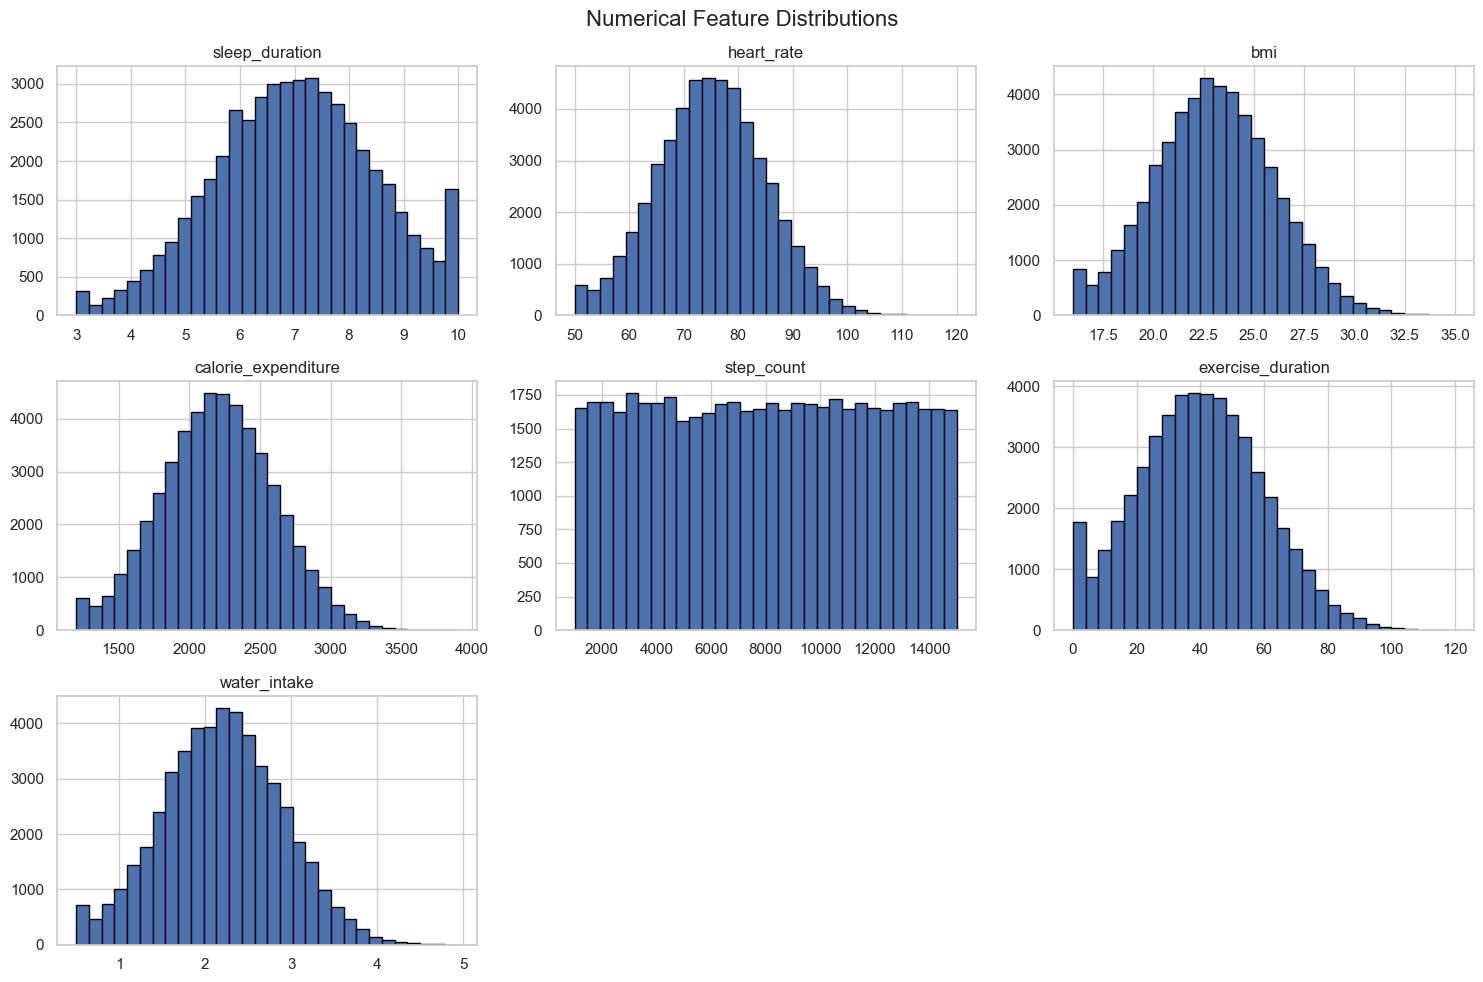

In [16]:
df[NUMERIC_FEATURES].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Numerical Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

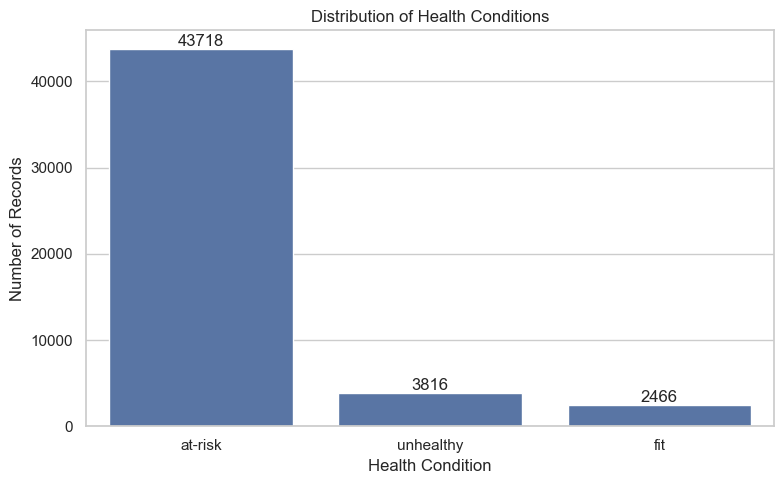

In [17]:
target_counts = df[TARGET].value_counts()

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=target_counts.index,
    y=target_counts.values
)

ax.set_title("Distribution of Health Conditions")
ax.set_xlabel("Health Condition")
ax.set_ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()

In [18]:
class_summary = pd.DataFrame({
    "count": df[TARGET].value_counts(),
    "percentage": (
        df[TARGET].value_counts(normalize=True) * 100
    )
})

display(class_summary.round(3))

imbalance_ratio = (
    class_summary["count"].max() /
    class_summary["count"].min()
)

print(f"Majority-to-minority ratio: {imbalance_ratio:.2f}:1")

,count,percentage
health_condition,,
at-risk,43718,87.436
unhealthy,3816,7.632
fit,2466,4.932


Majority-to-minority ratio: 17.73:1


C:\Users\kisha\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


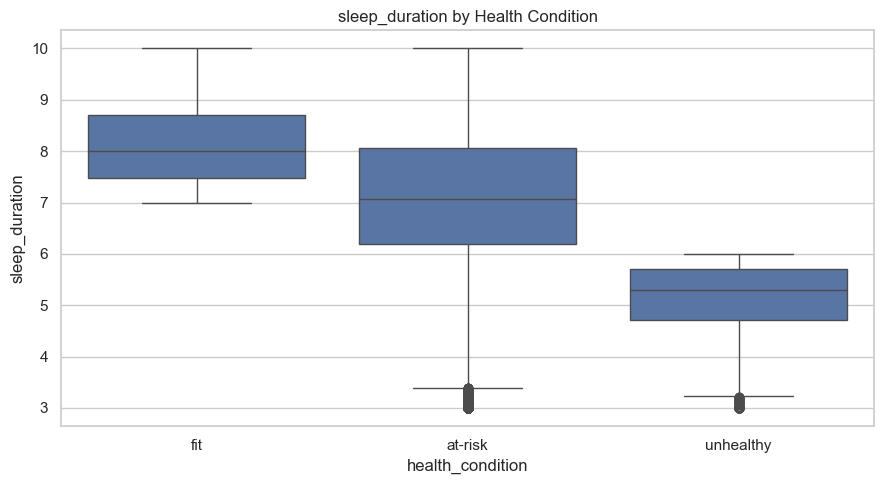

C:\Users\kisha\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


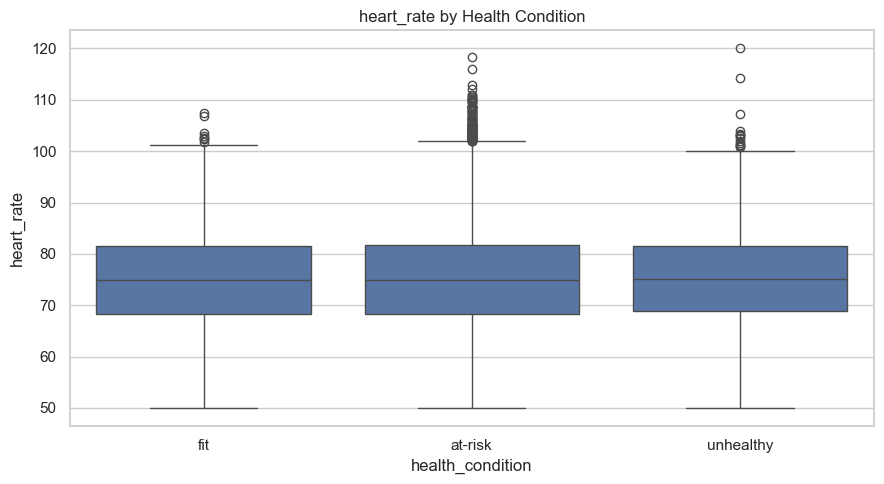

C:\Users\kisha\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


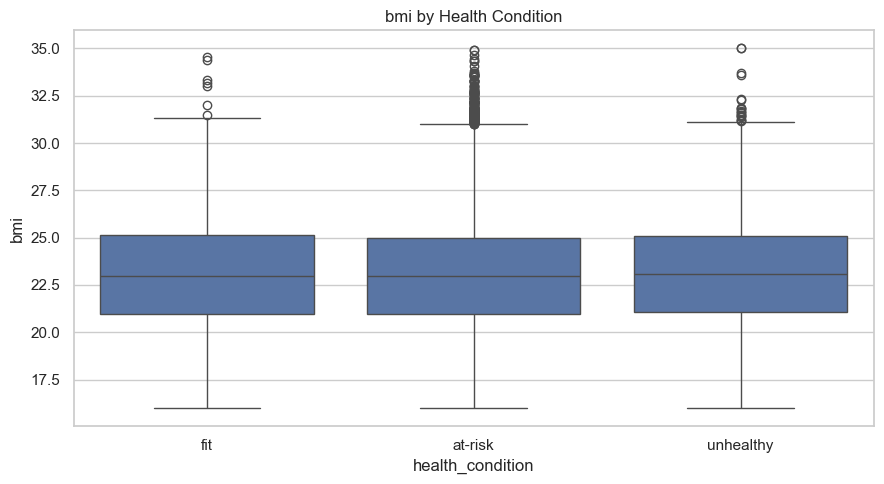

C:\Users\kisha\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


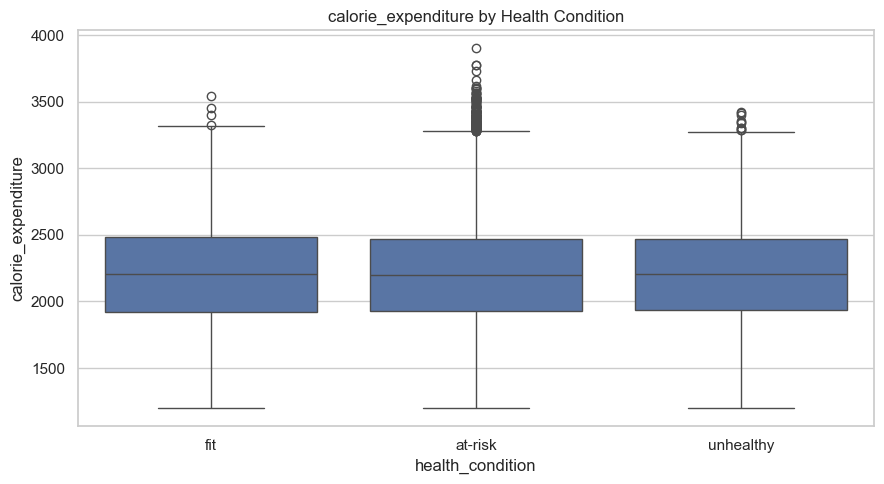

C:\Users\kisha\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


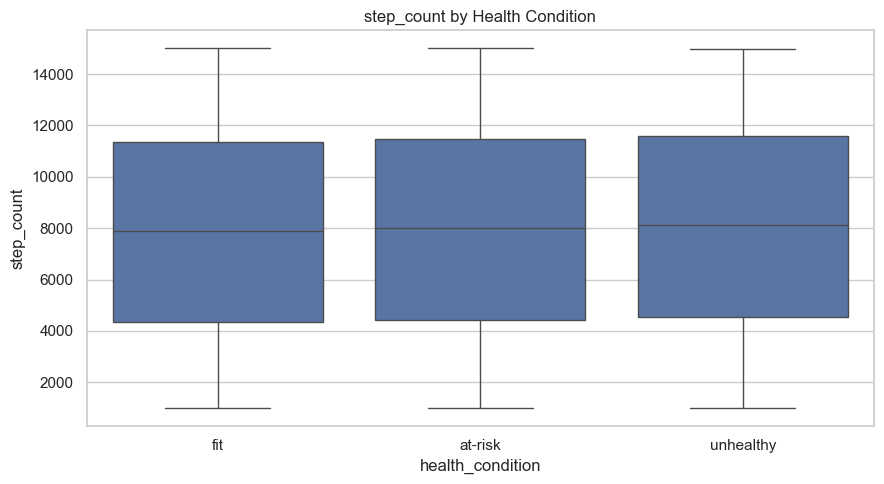

C:\Users\kisha\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


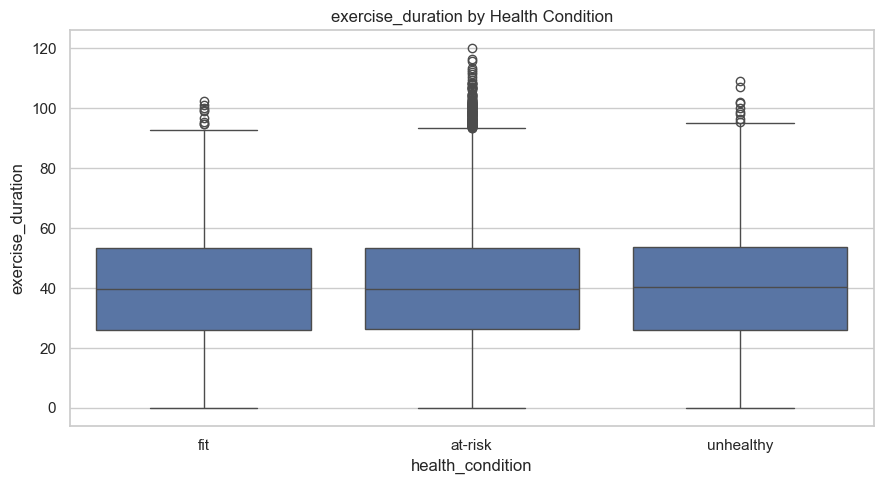

C:\Users\kisha\anaconda3\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


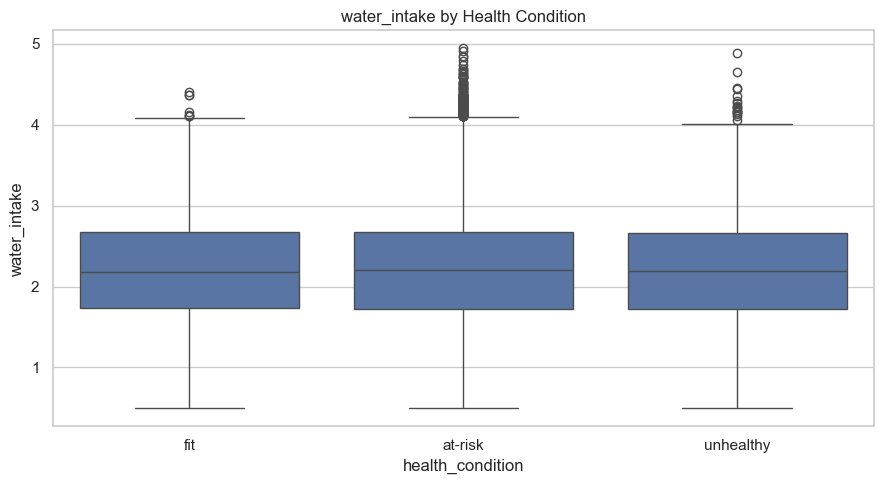

In [19]:
for col in NUMERIC_FEATURES:
    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x=TARGET,
        y=col,
        order=["fit", "at-risk", "unhealthy"]
    )

    plt.title(f"{col} by Health Condition")
    plt.tight_layout()
    plt.show()

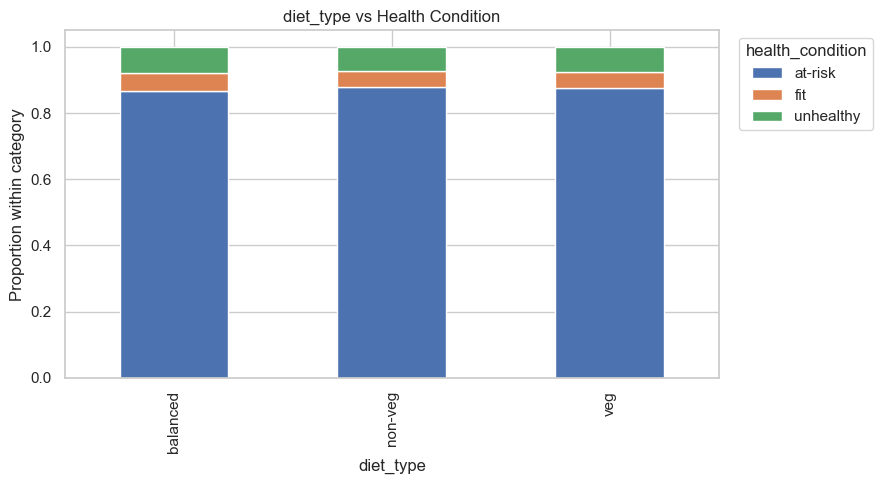

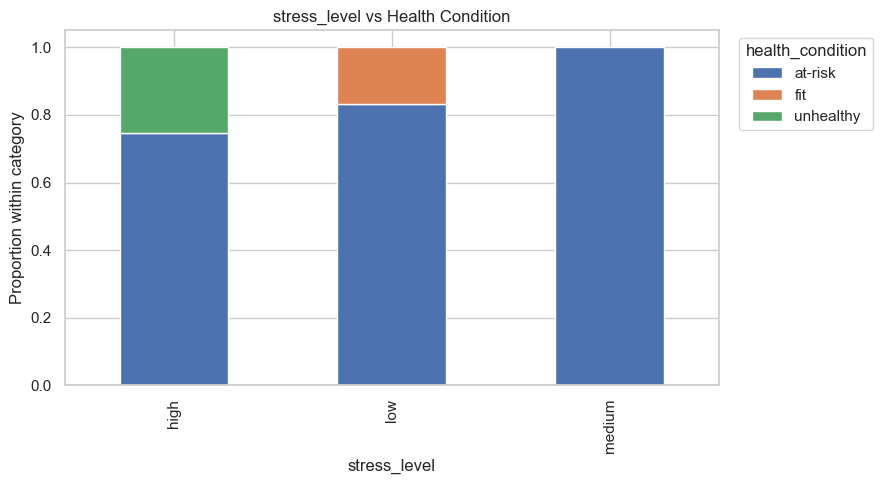

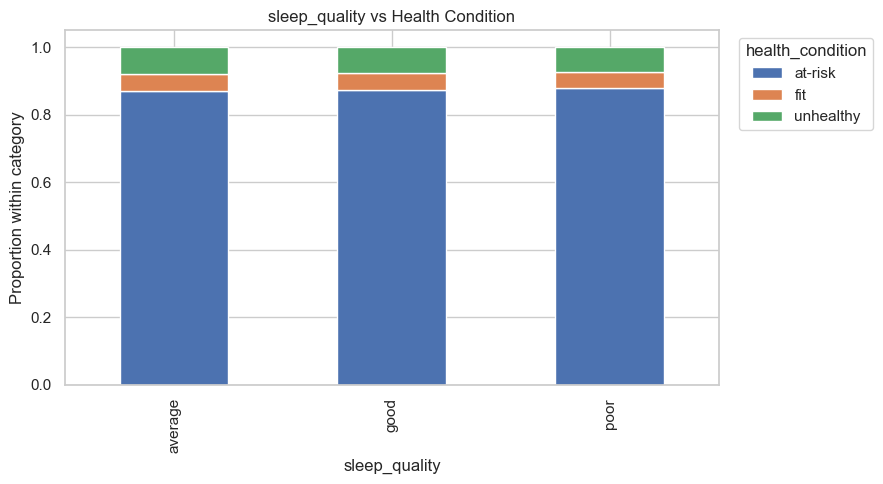

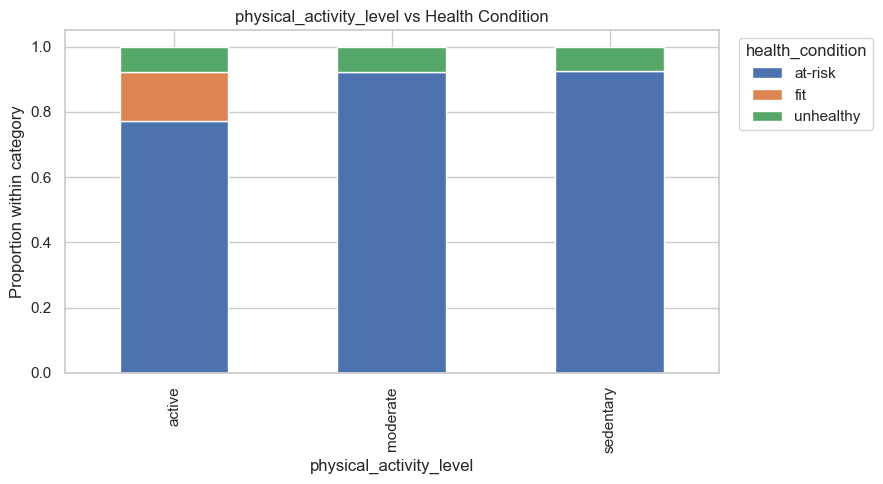

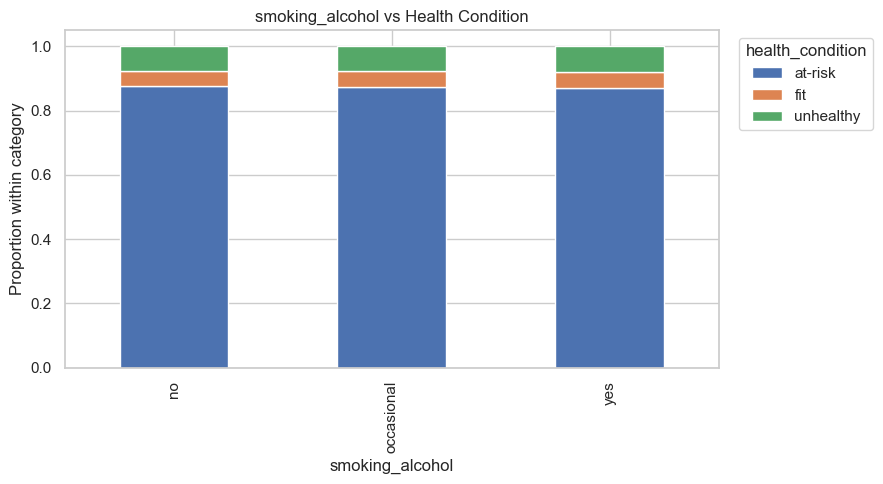

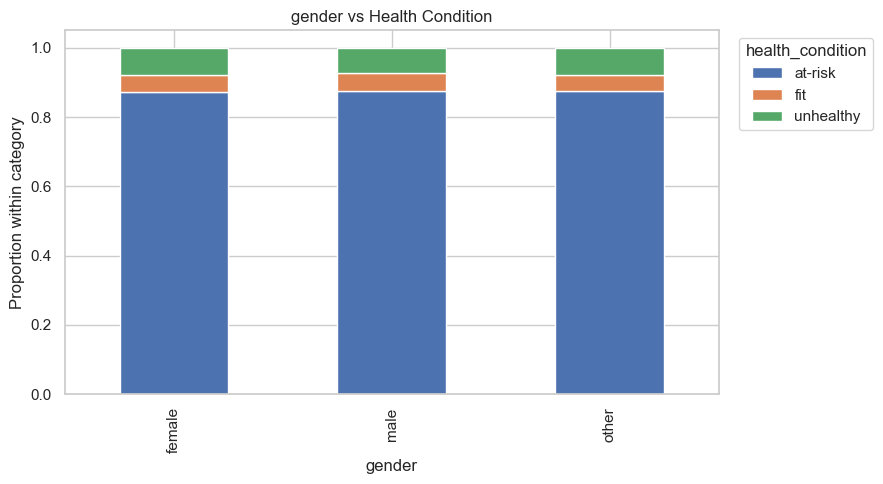

In [20]:
for col in CATEGORICAL_FEATURES:
    proportions = pd.crosstab(
        df[col],
        df[TARGET],
        normalize="index"
    )

    proportions.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5)
    )

    plt.title(f"{col} vs Health Condition")
    plt.xlabel(col)
    plt.ylabel("Proportion within category")
    plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

In [21]:
for col in ["stress_level", "physical_activity_level", "sleep_quality"]:
    print(f"\nTarget distribution within {col}:")

    display(
        pd.crosstab(
            df[col],
            df[TARGET],
            normalize="index"
        ).round(4)
    )

print("\nConditions that hold for every fit record:")

fit_rows = df[df[TARGET] == "fit"]

print(
    "All fit records have low stress:",
    bool((fit_rows["stress_level"] == "low").all())
)

print(
    "All fit records have active physical activity:",
    bool((fit_rows["physical_activity_level"] == "active").all())
)

unhealthy_rows = df[df[TARGET] == "unhealthy"]

print(
    "All unhealthy records have high stress:",
    bool((unhealthy_rows["stress_level"] == "high").all())
)


Target distribution within stress_level:


health_condition,at-risk,fit,unhealthy
stress_level,,,
high,0.7453,0.0000,0.2547
low,0.8336,0.1664,0.0000
medium,1.0000,0.0000,0.0000



Target distribution within physical_activity_level:


health_condition,at-risk,fit,unhealthy
physical_activity_level,,,
active,0.7731,0.1485,0.0784
moderate,0.9238,0.0000,0.0762
sedentary,0.9257,0.0000,0.0743



Target distribution within sleep_quality:


health_condition,at-risk,fit,unhealthy
sleep_quality,,,
average,0.8698,0.0509,0.0794
good,0.8740,0.0487,0.0773
poor,0.8793,0.0484,0.0723



Conditions that hold for every fit record:
All fit records have low stress: True
All fit records have active physical activity: True
All unhealthy records have high stress: True


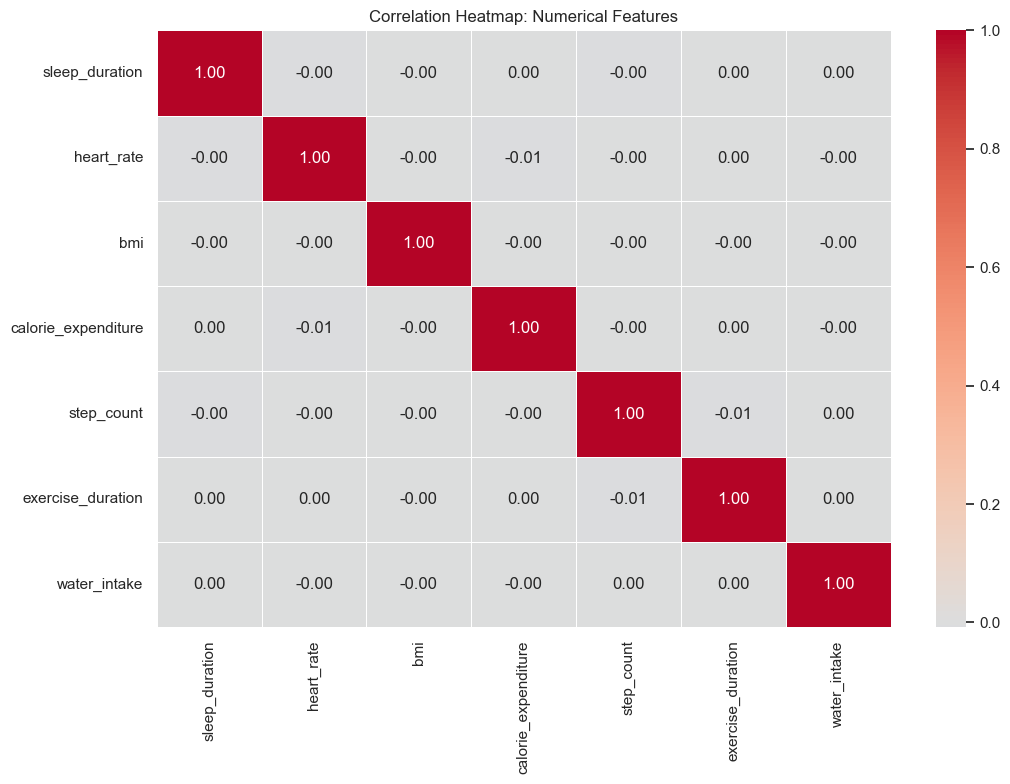

In [22]:
plt.figure(figsize=(11, 8))

correlation_matrix = df[NUMERIC_FEATURES].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap: Numerical Features")
plt.tight_layout()
plt.show()

In [23]:
print("Earliest timestamp:", df[TIME_COLUMN].min())
print("Latest timestamp:", df[TIME_COLUMN].max())

records_per_student = df.groupby(ID_COLUMN).size()

print("\nUnique students:", df[ID_COLUMN].nunique())
print("Minimum records per student:", records_per_student.min())
print("Median records per student:", records_per_student.median())
print("Maximum records per student:", records_per_student.max())

display(records_per_student.describe().to_frame("records_per_student"))

Earliest timestamp: 2025-01-01 00:00:00
Latest timestamp: 2030-09-15 07:00:00

Unique students: 1000
Minimum records per student: 29
Median records per student: 50.0
Maximum records per student: 73


,records_per_student
count,1000.000000
mean,50.000000
std,7.140237
min,29.000000
25%,45.000000
50%,50.000000
75%,55.000000
max,73.000000


In [24]:
print("Shape before cleaning:", df.shape)

df = df.dropna(subset=[TARGET, ID_COLUMN]).copy()

df = df.drop_duplicates().copy()

# IDs are required for grouping and should be valid.
df[ID_COLUMN] = pd.to_numeric(
    df[ID_COLUMN],
    errors="coerce"
)

df = df.dropna(subset=[ID_COLUMN]).copy()

print("Shape after cleaning:", df.shape)

assert df[TARGET].notna().all()
assert df[ID_COLUMN].notna().all()

print("Basic cleaning checks passed.")

Shape before cleaning: (50000, 16)
Shape after cleaning: (50000, 16)
Basic cleaning checks passed.


In [25]:
EXCLUDED_FEATURES = [
    ID_COLUMN,
    TIME_COLUMN,
    TARGET,
    "stress_level",
    "physical_activity_level",
]

FEATURE_COLUMNS = [
    col for col in df.columns
    if col not in EXCLUDED_FEATURES
]

X = df[FEATURE_COLUMNS].copy()
y = df[TARGET].copy()
groups = df[ID_COLUMN].copy()

print("Modeling feature columns:")
print(FEATURE_COLUMNS)

print("\nNumber of input features:", X.shape[1])
print("Number of target records:", y.shape[0])
print("Number of unique student groups:", groups.nunique())

display(X.head())

Modeling feature columns:
['sleep_duration', 'heart_rate', 'bmi', 'calorie_expenditure', 'step_count', 'exercise_duration', 'water_intake', 'diet_type', 'sleep_quality', 'smoking_alcohol', 'gender']

Number of input features: 11
Number of target records: 50000
Number of unique student groups: 1000


,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,sleep_quality,smoking_alcohol,gender
0,9.29,67.4,28.56,2113.0,5227,91.3,2.08,veg,average,yes,other
1,9.33,57.2,30.17,2060.0,14460,67.0,2.57,veg,average,occasional,male
2,8.33,73.7,19.93,2236.0,14589,52.6,1.93,non-veg,average,no,other
3,5.60,61.9,22.02,2650.0,12618,55.2,2.97,veg,average,no,other
4,9.10,69.6,20.85,1985.0,14518,27.1,3.09,non-veg,poor,occasional,male


In [26]:
NUMERIC_MODEL_FEATURES = [
    col for col in NUMERIC_FEATURES
    if col in FEATURE_COLUMNS
]

CATEGORICAL_MODEL_FEATURES = [
    col for col in CATEGORICAL_FEATURES
    if col in FEATURE_COLUMNS
]

print("Numerical model features:")
print(NUMERIC_MODEL_FEATURES)

print("\nCategorical model features:")
print(CATEGORICAL_MODEL_FEATURES)

assert set(NUMERIC_MODEL_FEATURES).isdisjoint(
    CATEGORICAL_MODEL_FEATURES
)

assert set(NUMERIC_MODEL_FEATURES + CATEGORICAL_MODEL_FEATURES) == set(
    FEATURE_COLUMNS
)

print("\nFeature grouping validation passed.")

Numerical model features:
['sleep_duration', 'heart_rate', 'bmi', 'calorie_expenditure', 'step_count', 'exercise_duration', 'water_intake']

Categorical model features:
['diet_type', 'sleep_quality', 'smoking_alcohol', 'gender']

Feature grouping validation passed.


In [27]:
from sklearn.model_selection import GroupShuffleSplit

all_classes = set(y.unique())
split_found = False

# Try deterministic splits until both partitions contain all classes.
for seed in range(RANDOM_STATE, RANDOM_STATE + 100):
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=seed
    )

    train_idx, test_idx = next(
        splitter.split(X, y, groups=groups)
    )

    y_train_candidate = y.iloc[train_idx]
    y_test_candidate = y.iloc[test_idx]

    if (
        set(y_train_candidate.unique()) == all_classes
        and set(y_test_candidate.unique()) == all_classes
    ):
        split_found = True
        selected_seed = seed
        break

if not split_found:
    raise ValueError(
        "Could not find a grouped split containing all classes "
        "in both partitions. Inspect class distribution by student."
    )

print("Selected random seed:", selected_seed)
print("Grouped split prepared successfully.")

Selected random seed: 42
Grouped split prepared successfully.


In [28]:
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("Training unique students:", groups_train.nunique())
print("Testing unique students:", groups_test.nunique())

Training feature shape: (40170, 11)
Testing feature shape: (9830, 11)
Training target shape: (40170,)
Testing target shape: (9830,)
Training unique students: 800
Testing unique students: 200


In [29]:
overlapping_students = set(groups_train) & set(groups_test)

print("Overlapping student IDs:", len(overlapping_students))

assert len(overlapping_students) == 0, (
    "Data leakage detected: students occur in both partitions."
)

assert len(X_train) + len(X_test) == len(X)
assert len(y_train) == len(X_train)
assert len(y_test) == len(X_test)

print("Train-test integrity checks passed.")

Overlapping student IDs: 0
Train-test integrity checks passed.


,full_dataset,training_set,testing_set
health_condition,,,
at-risk,87.44,87.44,87.44
unhealthy,7.63,7.7,7.36
fit,4.93,4.86,5.21


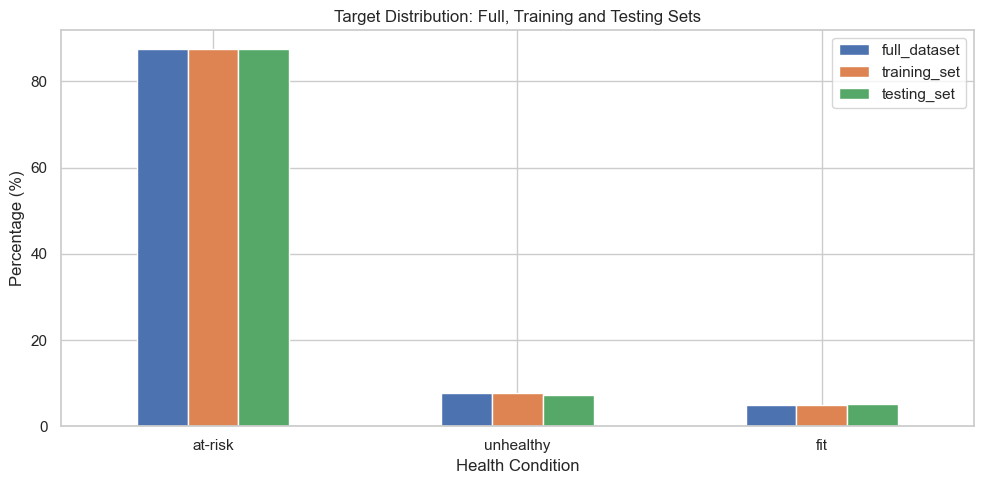

In [30]:
distribution = pd.DataFrame({
    "full_dataset": y.value_counts(normalize=True),
    "training_set": y_train.value_counts(normalize=True),
    "testing_set": y_test.value_counts(normalize=True),
}).fillna(0) * 100

distribution = distribution.round(2)

display(distribution)

distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Target Distribution: Full, Training and Testing Sets")
plt.ylabel("Percentage (%)")
plt.xlabel("Health Condition")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
classes = np.sort(y_train.unique())

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    cls: float(weight)
    for cls, weight in zip(classes, weights)
}

class_weight_table = pd.DataFrame({
    "class": classes,
    "training_count": [
        int((y_train == cls).sum()) for cls in classes
    ],
    "class_weight": [
        class_weights[cls] for cls in classes
    ]
})

display(class_weight_table)

print("Class weights:", class_weights)

,class,training_count,class_weight
0,at-risk,35123,0.381232
1,fit,1954,6.852610
2,unhealthy,3093,4.329130


Class weights: {'at-risk': 0.3812316715542522, 'fit': 6.852610030706243, 'unhealthy': 4.329130294212739}


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        ),
    ]
)

categorical_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_preprocessor,
            NUMERIC_MODEL_FEATURES
        ),
        (
            "categorical",
            categorical_preprocessor,
            CATEGORICAL_MODEL_FEATURES
        ),
    ],
    remainder="drop"
)

print("Preprocessing pipeline defined.")
print("No preprocessing has been fitted yet.")

Preprocessing pipeline defined.
No preprocessing has been fitted yet.


In [33]:
print("=" * 55)
print("FINAL PRE-TRAINING CHECK")
print("=" * 55)

print("Dataset shape:", df.shape)
print("Selected features:", len(FEATURE_COLUMNS))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining classes:")
print(y_train.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())

print("\nStudent overlap:", len(overlapping_students))
print("Missing targets in training:", y_train.isna().sum())
print("Missing targets in testing:", y_test.isna().sum())

assert len(overlapping_students) == 0
assert y_train.notna().all()
assert y_test.notna().all()
assert X_train.columns.equals(X_test.columns)
assert set(y_train.unique()) == set(y_test.unique())

print("\nAll final pre-training checks passed.")
print("Ready for the model training phase.")

FINAL PRE-TRAINING CHECK
Dataset shape: (50000, 16)
Selected features: 11
Training records: 40170
Testing records: 9830

Training classes:
health_condition
at-risk      35123
unhealthy     3093
fit           1954
Name: count, dtype: Int64

Testing classes:
health_condition
at-risk      8595
unhealthy     723
fit           512
Name: count, dtype: Int64

Student overlap: 0
Missing targets in training: 0
Missing targets in testing: 0

All final pre-training checks passed.
Ready for the model training phase.


In [34]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42

print("Modeling libraries imported successfully.")

Modeling libraries imported successfully.


In [35]:
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert len(groups_train) == len(X_train)
assert len(groups_test) == len(X_test)

assert len(set(groups_train) & set(groups_test)) == 0
assert X_train.columns.equals(X_test.columns)

assert set(y_train.unique()) == set(y_test.unique())

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

CLASS_NAMES = label_encoder.classes_
N_CLASSES = len(CLASS_NAMES)
ALL_CLASS_IDS = np.arange(N_CLASSES)

print("Class mapping:")
for class_id, class_name in enumerate(CLASS_NAMES):
    print(f"{class_id} -> {class_name}")

print("\nNumber of classes:", N_CLASSES)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training students:", groups_train.nunique())
print("Testing students:", groups_test.nunique())

print("\nTraining class counts:")
display(y_train.value_counts().rename("count").to_frame())

Class mapping:
0 -> at-risk
1 -> fit
2 -> unhealthy

Number of classes: 3
Training rows: 40170
Testing rows: 9830
Training students: 800
Testing students: 200

Training class counts:


,count
health_condition,
at-risk,35123
unhealthy,3093
fit,1954


In [36]:
# Preserve the original X_train and X_test variables.
X_train_model = X_train.copy()
X_test_model = X_test.copy()

# Convert categorical columns to standard Python object dtype.
# This improves compatibility with sklearn imputers and encoders.
for col in CATEGORICAL_MODEL_FEATURES:
    X_train_model[col] = X_train_model[col].astype(object)
    X_test_model[col] = X_test_model[col].astype(object)

# XGBoost: preprocessing and encoding are handled by the pipeline.
X_train_xgb = X_train_model.copy()
X_test_xgb = X_test_model.copy()

# CatBoost: retain native categorical variables.
X_train_cb = X_train_model.copy()
X_test_cb = X_test_model.copy()

for col in CATEGORICAL_MODEL_FEATURES:
    X_train_cb[col] = X_train_cb[col].where(
        X_train_cb[col].notna(), "Unknown"
    ).astype(str)

    X_test_cb[col] = X_test_cb[col].where(
        X_test_cb[col].notna(), "Unknown"
    ).astype(str)

# Ensure numerical columns contain numeric values.
for col in NUMERIC_MODEL_FEATURES:
    X_train_cb[col] = pd.to_numeric(
        X_train_cb[col], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    X_test_cb[col] = pd.to_numeric(
        X_test_cb[col], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

print("XGBoost and CatBoost input datasets are ready.")
print("XGBoost training shape:", X_train_xgb.shape)
print("CatBoost training shape:", X_train_cb.shape)

assert list(X_train_xgb.columns) == list(X_test_xgb.columns)
assert list(X_train_cb.columns) == list(X_test_cb.columns)

XGBoost and CatBoost input datasets are ready.
XGBoost training shape: (40170, 11)
CatBoost training shape: (40170, 11)


In [37]:
xgb_params = {
    "n_estimators": 450,
    "learning_rate": 0.03,
    "max_depth": 5,
    "min_child_weight": 3,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_alpha": 0.1,
    "reg_lambda": 3.0,
    "objective": "multi:softprob",
    "eval_metric": "mlogloss",
    "tree_method": "hist",
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

catboost_params = {
    "iterations": 600,
    "learning_rate": 0.03,
    "depth": 6,
    "loss_function": "MultiClass",
    "eval_metric": "MultiClass",
    "random_seed": RANDOM_STATE,
    "verbose": False,
    "allow_writing_files": False,
    "thread_count": -1
}

print("XGBoost configuration:")
print(xgb_params)

print("\nCatBoost configuration:")
print(catboost_params)

XGBoost configuration:
{'n_estimators': 450, 'learning_rate': 0.03, 'max_depth': 5, 'min_child_weight': 3, 'subsample': 0.85, 'colsample_bytree': 0.85, 'reg_alpha': 0.1, 'reg_lambda': 3.0, 'objective': 'multi:softprob', 'eval_metric': 'mlogloss', 'tree_method': 'hist', 'random_state': 42, 'n_jobs': -1}

CatBoost configuration:
{'iterations': 600, 'learning_rate': 0.03, 'depth': 6, 'loss_function': 'MultiClass', 'eval_metric': 'MultiClass', 'random_seed': 42, 'verbose': False, 'allow_writing_files': False, 'thread_count': -1}


In [38]:
group_cv = GroupKFold(n_splits=5)

cv_results = []

for fold, (fold_train_idx, fold_valid_idx) in enumerate(
    group_cv.split(X_train_model, y_train_encoded, groups_train),
    start=1
):
    print(f"\n{'=' * 20} FOLD {fold} {'=' * 20}")

    # Fold-specific data
    X_fold_train_xgb = X_train_xgb.iloc[fold_train_idx]
    X_fold_valid_xgb = X_train_xgb.iloc[fold_valid_idx]

    X_fold_train_cb = X_train_cb.iloc[fold_train_idx]
    X_fold_valid_cb = X_train_cb.iloc[fold_valid_idx]

    y_fold_train = y_train_encoded[fold_train_idx]
    y_fold_valid = y_train_encoded[fold_valid_idx]

    fold_groups_train = groups_train.iloc[fold_train_idx]
    fold_groups_valid = groups_train.iloc[fold_valid_idx]

    assert len(set(fold_groups_train) & set(fold_groups_valid)) == 0

    # Every class must be represented in the fold training data.
    fold_classes = np.unique(y_fold_train)

    if not np.array_equal(fold_classes, ALL_CLASS_IDS):
        raise ValueError(
            f"Fold {fold} is missing a training class. "
            "Inspect class distribution by student."
        )

    # Balanced sample weights calculated using this fold's training labels.
    fold_sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_fold_train
    )

    fold_class_weights = compute_class_weight(
        class_weight="balanced",
        classes=ALL_CLASS_IDS,
        y=y_fold_train
    )

    # ---------------- XGBoost ----------------
    xgb_pipeline_fold = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", XGBClassifier(**xgb_params))
    ])

    xgb_pipeline_fold.fit(
        X_fold_train_xgb,
        y_fold_train,
        model__sample_weight=fold_sample_weights
    )

    xgb_predictions = xgb_pipeline_fold.predict(
        X_fold_valid_xgb
    ).astype(int)

    # ---------------- CatBoost ----------------
    catboost_fold = CatBoostClassifier(
        **catboost_params,
        class_weights=fold_class_weights.tolist(),
        cat_features=CATEGORICAL_MODEL_FEATURES
    )

    catboost_fold.fit(
        X_fold_train_cb,
        y_fold_train
    )

    catboost_predictions = catboost_fold.predict(
        X_fold_valid_cb
    ).reshape(-1).astype(int)

    # Record validation metrics.
    for model_name, predictions in [
        ("XGBoost", xgb_predictions),
        ("CatBoost", catboost_predictions)
    ]:
        fold_result = {
            "fold": fold,
            "model": model_name,
            "balanced_accuracy": balanced_accuracy_score(
                y_fold_valid, predictions
            ),
            "macro_f1": f1_score(
                y_fold_valid,
                predictions,
                average="macro",
                zero_division=0
            ),
            "accuracy": accuracy_score(
                y_fold_valid, predictions
            )
        }

        cv_results.append(fold_result)

        print(
            f"{model_name}: "
            f"Balanced Accuracy = "
            f"{fold_result['balanced_accuracy']:.4f}, "
            f"Macro F1 = {fold_result['macro_f1']:.4f}, "
            f"Accuracy = {fold_result['accuracy']:.4f}"
        )

cv_results_df = pd.DataFrame(cv_results)

print("\nCross-validation completed.")


==================== FOLD 1 ====================
XGBoost: Balanced Accuracy = 0.7214, Macro F1 = 0.4003, Accuracy = 0.4565
CatBoost: Balanced Accuracy = 0.7457, Macro F1 = 0.3703, Accuracy = 0.3901

==================== FOLD 2 ====================
XGBoost: Balanced Accuracy = 0.7234, Macro F1 = 0.3937, Accuracy = 0.4459
CatBoost: Balanced Accuracy = 0.7526, Macro F1 = 0.3640, Accuracy = 0.3800

==================== FOLD 3 ====================
XGBoost: Balanced Accuracy = 0.7239, Macro F1 = 0.3953, Accuracy = 0.4563
CatBoost: Balanced Accuracy = 0.7446, Macro F1 = 0.3663, Accuracy = 0.3901

==================== FOLD 4 ====================
XGBoost: Balanced Accuracy = 0.7274, Macro F1 = 0.3836, Accuracy = 0.4350
CatBoost: Balanced Accuracy = 0.7458, Macro F1 = 0.3531, Accuracy = 0.3701

==================== FOLD 5 ====================
XGBoost: Balanced Accuracy = 0.7178, Macro F1 = 0.3986, Accuracy = 0.4536
CatBoost: Balanced Accuracy = 0.7572, Macro F1 = 0.3699, Accuracy = 0.3861

Cros

In [39]:
cv_summary = (
    cv_results_df
    .groupby("model")
    .agg(
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
        std_balanced_accuracy=("balanced_accuracy", "std"),
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean")
    )
    .sort_values("mean_macro_f1", ascending=False)
)

display(cv_summary.round(4))

best_model_name = cv_summary.index[0]

print("Selected model based on mean CV macro F1:", best_model_name)
print(
    "Mean CV macro F1:",
    round(cv_summary.loc[best_model_name, "mean_macro_f1"], 4)
)
print(
    "Mean CV balanced accuracy:",
    round(cv_summary.loc[best_model_name, "mean_balanced_accuracy"], 4)
)

,mean_balanced_accuracy,std_balanced_accuracy,mean_macro_f1,std_macro_f1,mean_accuracy
model,,,,,
XGBoost,0.7228,0.0035,0.3943,0.0065,0.4495
CatBoost,0.7492,0.0055,0.3647,0.0070,0.3833


Selected model based on mean CV macro F1: XGBoost
Mean CV macro F1: 0.3943
Mean CV balanced accuracy: 0.7228


In [40]:
if best_model_name == "XGBoost":

    best_model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", XGBClassifier(**xgb_params))
    ])

    final_sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train_encoded
    )

    best_model.fit(
        X_train_xgb,
        y_train_encoded,
        model__sample_weight=final_sample_weights
    )

else:

    final_class_weights = compute_class_weight(
        class_weight="balanced",
        classes=ALL_CLASS_IDS,
        y=y_train_encoded
    )

    best_model = CatBoostClassifier(
        **catboost_params,
        class_weights=final_class_weights.tolist(),
        cat_features=CATEGORICAL_MODEL_FEATURES
    )

    best_model.fit(
        X_train_cb,
        y_train_encoded
    )

print(f"{best_model_name} trained on the complete training set.")

XGBoost trained on the complete training set.


In [41]:
if best_model_name == "XGBoost":
    test_predictions = best_model.predict(
        X_test_xgb
    ).astype(int)

    test_probabilities = best_model.predict_proba(
        X_test_xgb
    )

else:
    test_predictions = best_model.predict(
        X_test_cb
    ).reshape(-1).astype(int)

    test_probabilities = best_model.predict_proba(
        X_test_cb
    )

test_metrics = {
    "model": best_model_name,
    "accuracy": accuracy_score(
        y_test_encoded, test_predictions
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_test_encoded, test_predictions
    ),
    "macro_precision": precision_score(
        y_test_encoded,
        test_predictions,
        average="macro",
        zero_division=0
    ),
    "macro_recall": recall_score(
        y_test_encoded,
        test_predictions,
        average="macro",
        zero_division=0
    ),
    "macro_f1": f1_score(
        y_test_encoded,
        test_predictions,
        average="macro",
        zero_division=0
    )
}

display(pd.DataFrame([test_metrics]).round(4))

print("\nDetailed classification report:\n")

print(
    classification_report(
        y_test_encoded,
        test_predictions,
        labels=ALL_CLASS_IDS,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,XGBoost,0.432,0.7368,0.459,0.7368,0.3896



Detailed classification report:

              precision    recall  f1-score   support

     at-risk       0.98      0.36      0.53      8595
         fit       0.10      0.86      0.18       512
   unhealthy       0.30      0.99      0.46       723

    accuracy                           0.43      9830
   macro avg       0.46      0.74      0.39      9830
weighted avg       0.88      0.43      0.50      9830



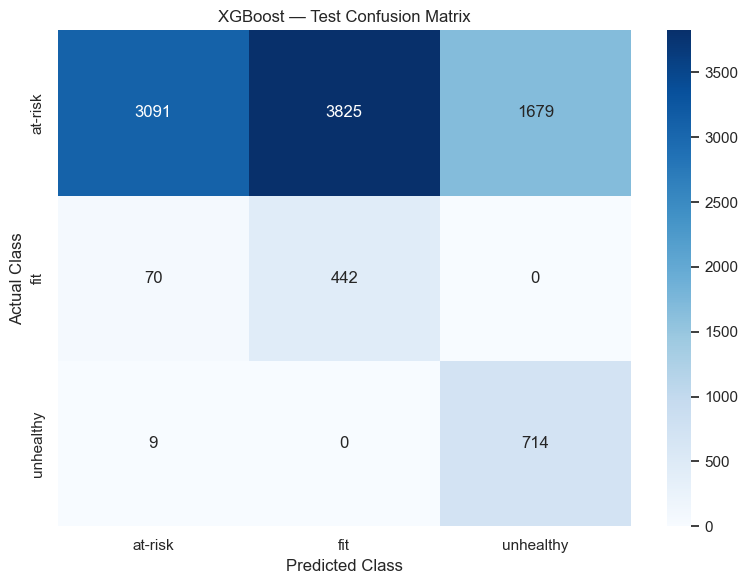

In [42]:
cm = confusion_matrix(
    y_test_encoded,
    test_predictions,
    labels=ALL_CLASS_IDS
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title(f"{best_model_name} — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

,feature,importance
0,numeric__sleep_duration,0.69695
5,numeric__exercise_duration,0.01842
13,categorical__smoking_alcohol_no,0.01818
2,numeric__bmi,0.01810
14,categorical__smoking_alcohol_occasional,0.01798
3,numeric__calorie_expenditure,0.01776
1,numeric__heart_rate,0.01771
6,numeric__water_intake,0.01749
9,categorical__diet_type_veg,0.01746
4,numeric__step_count,0.01720


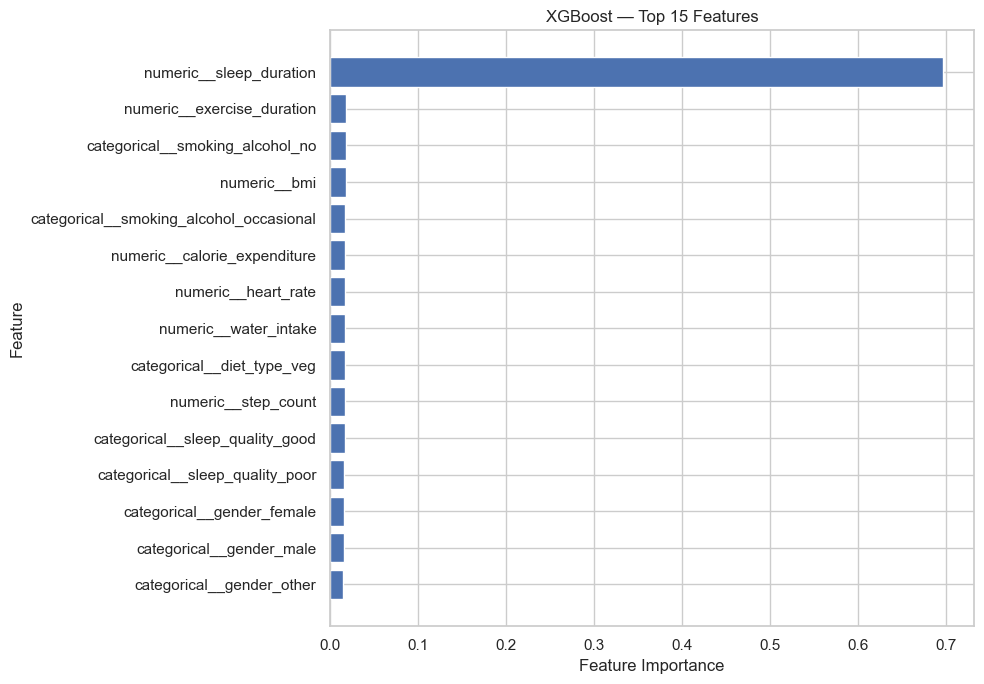

In [43]:
if best_model_name == "XGBoost":
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_estimator = best_model.named_steps["model"]

    importance_values = fitted_estimator.feature_importances_
    importance_names = fitted_preprocessor.get_feature_names_out()

else:
    importance_values = best_model.feature_importances_
    importance_names = X_train_cb.columns.to_numpy()

feature_importance_df = pd.DataFrame({
    "feature": importance_names,
    "importance": importance_values
}).sort_values("importance", ascending=False)

display(feature_importance_df.head(20).round(5))

top_features = feature_importance_df.head(15).sort_values(
    "importance", ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.title(f"{best_model_name} — Top 15 Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [44]:
from pathlib import Path
import joblib

MODEL_DIR = Path("sattva_model_artifacts")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

if best_model_name == "XGBoost":
    model_path = MODEL_DIR / "sattva_health_xgboost.joblib"
    joblib.dump(best_model, model_path)

else:
    model_path = MODEL_DIR / "sattva_health_catboost.cbm"
    best_model.save_model(str(model_path))

# Save label mapping and required input schema.
metadata = {
    "model_name": best_model_name,
    "target": TARGET,
    "classes": CLASS_NAMES.tolist(),
    "feature_columns": FEATURE_COLUMNS,
    "numeric_features": NUMERIC_MODEL_FEATURES,
    "categorical_features": CATEGORICAL_MODEL_FEATURES,
    "excluded_features": EXCLUDED_FEATURES,
    "random_state": RANDOM_STATE,
    "selected_cv_macro_f1": float(
        cv_summary.loc[best_model_name, "mean_macro_f1"]
    ),
    "test_metrics": test_metrics
}

joblib.dump(
    metadata,
    MODEL_DIR / "sattva_health_metadata.joblib"
)

print("Model saved to:", model_path.resolve())
print("Metadata saved to:", (MODEL_DIR / "sattva_health_metadata.joblib").resolve())

Model saved to: C:\Users\kisha\Sattva\sattva_model_artifacts\sattva_health_xgboost.joblib
Metadata saved to: C:\Users\kisha\Sattva\sattva_model_artifacts\sattva_health_metadata.joblib


In [45]:
EXTRA_FEATURES = [
    "stress_level",
    "physical_activity_level"
]

X_train_full = pd.concat(
    [
        X_train.copy(),
        df.loc[X_train.index, EXTRA_FEATURES].copy()
    ],
    axis=1
)

X_test_full = pd.concat(
    [
        X_test.copy(),
        df.loc[X_test.index, EXTRA_FEATURES].copy()
    ],
    axis=1
)

NUMERIC_FULL = NUMERIC_MODEL_FEATURES.copy()

CATEGORICAL_FULL = (
    CATEGORICAL_MODEL_FEATURES + EXTRA_FEATURES
)

for col in CATEGORICAL_FULL:
    X_train_full[col] = X_train_full[col].astype(object)
    X_test_full[col] = X_test_full[col].astype(object)

for col in NUMERIC_FULL:
    X_train_full[col] = pd.to_numeric(
        X_train_full[col], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    X_test_full[col] = pd.to_numeric(
        X_test_full[col], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

preprocessor_full = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            NUMERIC_FULL
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            CATEGORICAL_FULL
        )
    ],
    remainder="drop"
)

X_train_full_cb = X_train_full.copy()
X_test_full_cb = X_test_full.copy()

for col in CATEGORICAL_FULL:
    X_train_full_cb[col] = (
        X_train_full_cb[col]
        .where(X_train_full_cb[col].notna(), "Unknown")
        .astype(str)
    )

    X_test_full_cb[col] = (
        X_test_full_cb[col]
        .where(X_test_full_cb[col].notna(), "Unknown")
        .astype(str)
    )

print("Expanded training features:", X_train_full.shape)
print("Expanded testing features:", X_test_full.shape)
print("New categorical features:", CATEGORICAL_FULL)

Expanded training features: (40170, 13)
Expanded testing features: (9830, 13)
New categorical features: ['diet_type', 'sleep_quality', 'smoking_alcohol', 'gender', 'stress_level', 'physical_activity_level']


In [46]:
from sklearn.model_selection import GroupKFold
from sklearn.base import clone

cv = GroupKFold(n_splits=5)
experiment_results = []

for fold, (tr, va) in enumerate(
    cv.split(X_train_full, y_train_encoded, groups_train),
    start=1
):
    Xtr = X_train_full.iloc[tr]
    Xva = X_train_full.iloc[va]

    Xtr_cb = X_train_full_cb.iloc[tr]
    Xva_cb = X_train_full_cb.iloc[va]

    ytr = y_train_encoded[tr]
    yva = y_train_encoded[va]

    assert set(groups_train.iloc[tr]).isdisjoint(
        set(groups_train.iloc[va])
    )

    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=ytr
    )

    class_weights_fold = compute_class_weight(
        class_weight="balanced",
        classes=ALL_CLASS_IDS,
        y=ytr
    )

    # XGBoost: no class weights
    xgb_plain = Pipeline([
        ("preprocessor", clone(preprocessor_full)),
        ("model", XGBClassifier(**xgb_params))
    ])
    xgb_plain.fit(Xtr, ytr)

    # XGBoost: balanced sample weights
    xgb_weighted = Pipeline([
        ("preprocessor", clone(preprocessor_full)),
        ("model", XGBClassifier(**xgb_params))
    ])
    xgb_weighted.fit(
        Xtr, ytr,
        model__sample_weight=sample_weights
    )

    # CatBoost: no class weights
    cb_plain = CatBoostClassifier(
        **catboost_params,
        cat_features=CATEGORICAL_FULL
    )
    cb_plain.fit(Xtr_cb, ytr)

    # CatBoost: balanced class weights
    cb_weighted = CatBoostClassifier(
        **catboost_params,
        class_weights=class_weights_fold.tolist(),
        cat_features=CATEGORICAL_FULL
    )
    cb_weighted.fit(Xtr_cb, ytr)

    fold_models = {
        "XGBoost_unweighted": (
            xgb_plain, Xva
        ),
        "XGBoost_weighted": (
            xgb_weighted, Xva
        ),
        "CatBoost_unweighted": (
            cb_plain, Xva_cb
        ),
        "CatBoost_weighted": (
            cb_weighted, Xva_cb
        )
    }

    for name, (model, valid_data) in fold_models.items():
        pred = np.asarray(model.predict(valid_data)).reshape(-1).astype(int)

        experiment_results.append({
            "fold": fold,
            "model": name,
            "macro_f1": f1_score(
                yva, pred, average="macro", zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(
                yva, pred
            ),
            "accuracy": accuracy_score(yva, pred)
        })

    print(f"Completed fold {fold}/5")

experiment_df = pd.DataFrame(experiment_results)

experiment_summary = (
    experiment_df.groupby("model")
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
        mean_accuracy=("accuracy", "mean")
    )
    .sort_values("mean_macro_f1", ascending=False)
)

display(experiment_summary.round(4))

Completed fold 1/5
Completed fold 2/5
Completed fold 3/5
Completed fold 4/5
Completed fold 5/5


,mean_macro_f1,std_macro_f1,mean_balanced_accuracy,mean_accuracy
model,,,,
XGBoost_unweighted,0.9998,0.0004,0.9998,0.9999
CatBoost_weighted,0.9992,0.0005,0.9999,0.9997
CatBoost_unweighted,0.9992,0.0005,0.9996,0.9997
XGBoost_weighted,0.9978,0.0013,0.9984,0.9991


In [47]:
best_experiment = experiment_summary.index[0]

print("Best configuration by CV macro F1:", best_experiment)
print(
    "Mean CV macro F1:",
    round(experiment_summary.iloc[0]["mean_macro_f1"], 4)
)
print(
    "Mean CV balanced accuracy:",
    round(
        experiment_summary.iloc[0]["mean_balanced_accuracy"], 4
    )
)

Best configuration by CV macro F1: XGBoost_unweighted
Mean CV macro F1: 0.9998
Mean CV balanced accuracy: 0.9998


In [48]:
# Check the relationship between added features and target labels

for col in ["stress_level", "physical_activity_level"]:
    print(f"\nTarget distribution by {col}:")

    display(
        pd.crosstab(
            df[col],
            df[TARGET],
            normalize="index"
        ).round(4)
    )

# Check whether combinations uniquely identify the target
print("\nUnique target labels per feature combination:")

for cols in [
    ["stress_level"],
    ["physical_activity_level"],
    ["stress_level", "physical_activity_level"]
]:
    combinations = df.groupby(cols, dropna=False)[TARGET].nunique()

    print(
        f"{cols}:",
        int((combinations == 1).sum()),
        "of",
        len(combinations),
        "combinations map to only one target class"
    )


Target distribution by stress_level:


health_condition,at-risk,fit,unhealthy
stress_level,,,
high,0.7453,0.0000,0.2547
low,0.8336,0.1664,0.0000
medium,1.0000,0.0000,0.0000



Target distribution by physical_activity_level:


health_condition,at-risk,fit,unhealthy
physical_activity_level,,,
active,0.7731,0.1485,0.0784
moderate,0.9238,0.0000,0.0762
sedentary,0.9257,0.0000,0.0743



Unique target labels per feature combination:
['stress_level']: 1 of 3 combinations map to only one target class
['physical_activity_level']: 0 of 3 combinations map to only one target class
['stress_level', 'physical_activity_level']: 5 of 9 combinations map to only one target class


Final XGBoost Test Results
Accuracy: 0.9998
Balanced Accuracy: 0.9993
Macro F1: 0.9993

Classification Report:

              precision    recall  f1-score   support

     at-risk       1.00      1.00      1.00      8595
         fit       1.00      1.00      1.00       512
   unhealthy       1.00      1.00      1.00       723

    accuracy                           1.00      9830
   macro avg       1.00      1.00      1.00      9830
weighted avg       1.00      1.00      1.00      9830



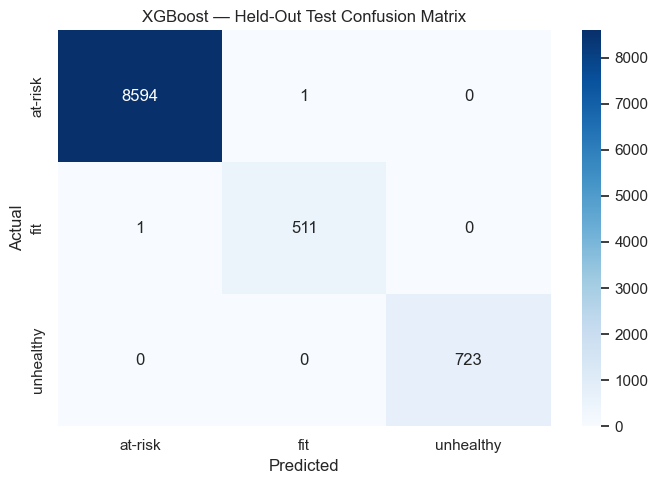

In [49]:
# Cell 50: Final XGBoost training and held-out test evaluation

best_xgb = Pipeline([
    ("preprocessor", clone(preprocessor_full)),
    ("model", XGBClassifier(**xgb_params))
])

# Train only on the existing training set.
best_xgb.fit(X_train_full, y_train_encoded)

# Evaluate on the untouched test set.
y_pred_final = best_xgb.predict(X_test_full).astype(int)

print("Final XGBoost Test Results")
print("=" * 50)

print(
    "Accuracy:",
    round(accuracy_score(y_test_encoded, y_pred_final), 4)
)
print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(y_test_encoded, y_pred_final), 4)
)
print(
    "Macro F1:",
    round(
        f1_score(
            y_test_encoded,
            y_pred_final,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_encoded,
        y_pred_final,
        labels=ALL_CLASS_IDS,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

cm_final = confusion_matrix(
    y_test_encoded,
    y_pred_final,
    labels=ALL_CLASS_IDS
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("XGBoost — Held-Out Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

,feature,importance
19,categorical__stress_level_high,0.20989
24,categorical__physical_activity_level_sedentary,0.20146
21,categorical__stress_level_medium,0.16021
23,categorical__physical_activity_level_moderate,0.11322
20,categorical__stress_level_low,0.11198
22,categorical__physical_activity_level_active,0.10820
0,numeric__sleep_duration,0.08870
8,categorical__diet_type_non-veg,0.00158
18,categorical__gender_other,0.00090
3,numeric__calorie_expenditure,0.00053


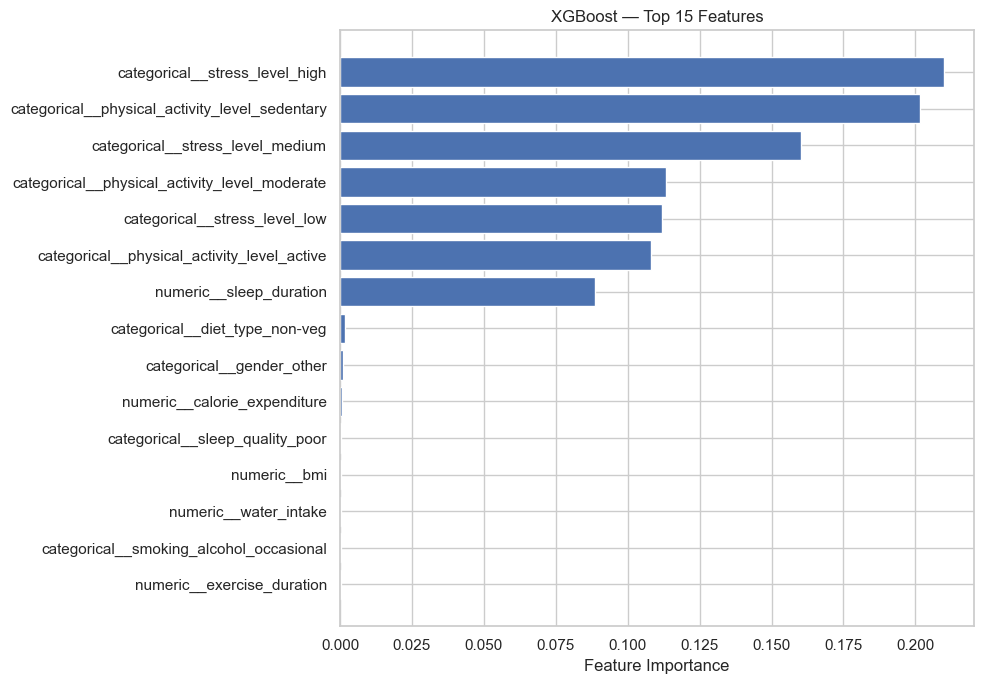

In [50]:
# Extract feature importance after preprocessing
fitted_preprocessor = best_xgb.named_steps["preprocessor"]
fitted_xgb = best_xgb.named_steps["model"]

importance_df = pd.DataFrame({
    "feature": fitted_preprocessor.get_feature_names_out(),
    "importance": fitted_xgb.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df.head(20).round(5))

plt.figure(figsize=(10, 7))

top_features = importance_df.head(15).sort_values("importance")

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.title("XGBoost — Top 15 Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [51]:
from pathlib import Path
import joblib
import json

MODEL_DIR = Path("sattva_model_artifacts")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the complete pipeline, including preprocessing.
model_path = MODEL_DIR / "sattva_health_xgboost.joblib"
joblib.dump(best_xgb, model_path)

# Save metadata for inference and backend integration.
metadata = {
    "model_name": "XGBoost",
    "target": TARGET,
    "classes": CLASS_NAMES.tolist(),
    "feature_columns": X_train_full.columns.tolist(),
    "numeric_features": NUMERIC_FULL,
    "categorical_features": CATEGORICAL_FULL,
    "excluded_features": [ID_COLUMN, TIME_COLUMN],
    "test_accuracy": float(
        accuracy_score(y_test_encoded, y_pred_final)
    ),
    "test_balanced_accuracy": float(
        balanced_accuracy_score(y_test_encoded, y_pred_final)
    ),
    "test_macro_f1": float(
        f1_score(
            y_test_encoded,
            y_pred_final,
            average="macro",
            zero_division=0
        )
    )
}

metadata_path = MODEL_DIR / "sattva_health_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print("Model saved:", model_path.resolve())
print("Metadata saved:", metadata_path.resolve())

Model saved: C:\Users\kisha\Sattva\sattva_model_artifacts\sattva_health_xgboost.joblib
Metadata saved: C:\Users\kisha\Sattva\sattva_model_artifacts\sattva_health_metadata.json


In [52]:
import joblib
import pandas as pd
from pathlib import Path

# 1. Load the saved model
model_path = Path("sattva_model_artifacts/sattva_health_xgboost.joblib")
loaded_model = joblib.load(model_path)

# 2. Select one unseen test example
sample = X_test_full.iloc[[0]].copy()
actual_label = y_test.iloc[0]

# 3. Generate prediction
predicted_encoded = int(loaded_model.predict(sample)[0])
predicted_label = label_encoder.inverse_transform(
    [predicted_encoded]
)[0]

# 4. Get class probabilities
probabilities = loaded_model.predict_proba(sample)[0]

probability_table = pd.DataFrame({
    "health_condition": CLASS_NAMES,
    "probability": probabilities
}).sort_values("probability", ascending=False)

# 5. Display results
print("Actual label:   ", actual_label)
print("Predicted label:", predicted_label)
print("Correct prediction:", actual_label == predicted_label)

print("\nPrediction probabilities:")
display(probability_table.reset_index(drop=True))

print("\nInput example:")
display(sample)

Actual label:    at-risk
Predicted label: at-risk
Correct prediction: True

Prediction probabilities:


,health_condition,probability
0,at-risk,0.999976
1,fit,0.000014
2,unhealthy,0.000010



Input example:


,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,sleep_quality,smoking_alcohol,gender,stress_level,physical_activity_level
82,6.61,68.0,25.81,1874.0,9167,58.4,2.25,balanced,average,yes,other,medium,active
